# Previsão da volatilidade futura: PETR4 e USD/BRL
**2035003 — Aprendizado de Máquina, PPGCC/UFJF · 24/09/2026**

Duas bases econômicas distintas: ação PETR4 (alvo principal) e cotação USD/BRL PTAX (segundo alvo). A série FRED DEXBZUS do mesmo câmbio foi escolhida **antes** da avaliação final como preditor externo da PETR4 em uma busca documentada. A segunda base independente é avaliada com alvo próprio. Etapa clássica concluída; zero-shot e few-shot ficaram para a etapa final, conforme orientação. Previsão após fechamento da B3, horizonte de cinco pregões.

In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as im
import numpy as np, pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd(); DATA=ROOT/'dados'; OUT=ROOT
pd.set_option('display.max_columns',30)
print('Python',sys.version.split()[0], 'pandas',pd.__version__,'numpy',np.__version__,'sklearn',im.version('scikit-learn'),'yfinance',im.version('yfinance'))
print('Coleta PETR4/brapi, BCB PTAX e FRED: 24/09/2026; semente: 42')

Python 3.12.14 pandas 2.2.3 numpy 2.3.5 sklearn 1.8.0 yfinance 1.7.0
Coleta PETR4/brapi, BCB PTAX e FRED: 24/09/2026; semente: 42


In [2]:
def read_petr():
 a=pd.read_csv(DATA/'petr4_brapi_max.csv',parse_dates=['Date']).rename(columns={'adjustedClose':'AdjClose','open':'Open','high':'High','low':'Low','close':'Close','volume':'Volume'})
 a=a[(a.Date>='2016-01-01')&(a.Date<='2025-12-31')].sort_values('Date')
 print('PETR4 bruto:',len(a),'datas repetidas:',a.Date.duplicated().sum(),'volume zero:',sum(a.Volume==0),'preços inválidos:',sum((a[['Open','High','Low','Close','AdjClose']]<=0).any(axis=1)))
 return a.drop_duplicates('Date',keep='last').loc[lambda x:(x.Volume>0)&(x[['Open','High','Low','Close','AdjClose']]>0).all(axis=1)].set_index('Date')
def read_fx():
 a=pd.read_csv(DATA/'BCB_PTAX_USDBRL.csv',parse_dates=['Date']).rename(columns={'value':'AdjClose'}).sort_values('Date')
 print('USD/BRL PTAX bruto:',len(a),'datas repetidas:',a.Date.duplicated().sum(),'nulos:',a.AdjClose.isna().sum(),'preços inválidos:',sum(a.AdjClose<=0))
 return a.drop_duplicates('Date',keep='last').dropna(subset=['AdjClose']).loc[lambda x:x.AdjClose>0].set_index('Date')
pet=read_petr();fx=read_fx()
for name,a in [('PETR4',pet),('USD/BRL',fx)]:
 assert a.index.is_monotonic_increasing and not a.index.has_duplicates
 print(name,'datas:',a.index.min().date(),a.index.max().date(),'maiores retornos absolutos:')
 display(np.log(a.AdjClose/a.AdjClose.shift()).abs().nlargest(5))

PETR4 bruto: 2483 datas repetidas: 0 volume zero: 0 preços inválidos: 0
USD/BRL PTAX bruto: 2510 datas repetidas: 0 nulos: 0 preços inválidos: 0
PETR4 datas: 2016-01-04 2025-12-30 maiores retornos absolutos:
USD/BRL datas: 2016-01-04 2025-12-31 maiores retornos absolutos:


Date
2020-03-09    0.352353
2021-02-22    0.242254
2020-03-12    0.229483
2020-03-13    0.200687
2017-05-18    0.171478

Date
2017-05-18    0.084232
2020-11-09    0.046099
2016-03-17    0.043859
2020-03-12    0.043849
2020-03-16    0.043566

## Alvo, atributos e referências
Para cada base, $r_t=\ln(P_t/P_{t-1})$ e $y_t=100\operatorname{std}_{ddof=1}(r_{t+1},\ldots,r_{t+5})$, em pontos percentuais diários. O cálculo requer cinco retornos futuros completos. HV5 usa apenas os cinco pregões até $t$. Para PETR4, o fechamento **ajustado** é obrigatório; high/low e volume são atributos observados. Para câmbio, a PTAX de venda é publicada pelo Banco Central antes do fechamento da B3; usamos somente preço de fechamento. Os extremos de mercado são preservados.

In [3]:
def build_base(a):
 d=pd.DataFrame(index=a.index);p=a.AdjClose
 r=np.log(p/p.shift());d['ret']=r;d['absret']=r.abs();d['sqret']=r*r
 d['amp']=np.log(a.High/a.Low) if {'High','Low'}.issubset(a.columns) else np.nan
 d['volchg']=np.log(a.Volume/a.Volume.shift()) if 'Volume' in a.columns else np.nan
 d['amp5']=d.amp.rolling(5).mean()
 for w in [5,10,20,30]:d[f'HV{w}']=100*r.rolling(w).std(ddof=1)
 for lag in range(30):d[f'ret_lag{lag}']=r.shift(lag)
 future=pd.concat([r.shift(-k) for k in range(1,6)],axis=1)
 d['y']=100*future.std(axis=1,ddof=1);d.loc[future.isna().any(axis=1),'y']=np.nan
 d['TargetEnd']=pd.Series(a.index,index=a.index).shift(-5)
 assert np.allclose(d.loc[d.y.notna(),'y'],100*future.loc[d.y.notna()].std(axis=1,ddof=1))
 return d
P0=build_base(pet);F0=build_base(fx)
BASIC=['ret','amp','volchg','HV30'];EXT=['ret','absret','sqret','amp','amp5','volchg','HV5','HV10','HV20','HV30'];RAW=[f'ret_lag{k}' for k in range(30)]
COMMON=['ret','absret','sqret','HV5','HV10','HV20','HV30']
print('Alvos completos: PETR4',P0.y.notna().sum(),'USD/BRL',F0.y.notna().sum());display(P0[['y','HV5','TargetEnd']].dropna().head(3))

Alvos completos: PETR4 2478 USD/BRL 2505


                   y       HV5  TargetEnd
Date                                     
2016-01-11  7.225965  1.625043 2016-01-18
2016-01-12  6.694770  3.654295 2016-01-19
2016-01-13  6.708376  3.680356 2016-01-20

## Seleção do segundo ativo por previsibilidade incremental da PETR4
Os scripts anexos `candidate_screen_bcb.py` e `candidate_ablation.py` reproduzem a busca. Foram consideradas 23 séries (ações, ETFs, índices, volatilidade implícita, commodities, juros e câmbio); cinco foram rejeitadas por descontinuidade de preço bruto, cotação não positiva ou cobertura. Antes de testar 2024–2025, a comparação usou a mesma interseção de datas, 4 folds expansivos com gap=5 até 2022 e confirmação independente em 2023. Cada candidato concorreu com três pequenos conjuntos de atributos e dois modelos fixos, sempre contra PETR4-only da mesma família. Critério: redução média do MAE na triagem, melhora em ≥3/4 folds, redução do MAE em 2023 e RMSE sem piora >3%. O USD/BRL FRED com atributos de risco e Random Forest teve a maior redução confirmada; BCB PTAX, IBOV e BOVA11 também constam. A série FRED de USD/BRL é incorporada semanalmente: defasamos cada observação 10 dias corridos antes de usá-la, com limite de idade; isso é uma aproximação conservadora do instante de publicação, não um registro point-in-time perfeito. A PTAX BCB entra como *segundo alvo*, em experimento separado.

In [4]:
ab=pd.read_csv(DATA/'busca_ablation.csv');audit=pd.read_csv(DATA/'auditoria_candidatos.csv')
print('Séries retidas na triagem:',len(audit),'comparações de ablação:',len(ab))
display(ab[ab.Robusto].sort_values('Delta_2023')[['Candidato','Preset','Modelo','MAE_base_screen','MAE_screen','Delta_screen','Folds_melhora','MAE_base_2023','MAE_2023','Delta_2023','RMSE_screen','RMSE_2023']].round(4))
assert ab.loc[(ab.Candidato=='USD_BRL_FRED')&(ab.Preset=='risk')&(ab.Modelo=='RF'),'Robusto'].iloc[0]


Séries retidas na triagem: 18 comparações de ablação: 108


       Candidato Preset  Modelo  MAE_base_screen  MAE_screen  Delta_screen  Folds_melhora  MAE_base_2023  MAE_2023  Delta_2023  RMSE_screen  RMSE_2023
27  USD_BRL_FRED   risk      RF           0.9961      0.9854       -0.0108              3         0.7323    0.7066     -0.0257       1.6353     0.8821
36          IBOV  shock  Linear           0.9713      0.9685       -0.0028              4         0.7514    0.7496     -0.0018       1.5866     0.9021
78        BOVA11  shock  Linear           0.9713      0.9687       -0.0026              4         0.7514    0.7506     -0.0008       1.5863     0.9030

In [5]:
e=pd.read_csv(DATA/'DEXBZUS.csv');e.columns=['ObsDate','value'];e.ObsDate=pd.to_datetime(e.ObsDate);e.value=pd.to_numeric(e.value,errors='coerce')
e=e.dropna().sort_values('ObsDate').drop_duplicates('ObsDate');rr=np.log(e.value/e.value.shift())
e['FX_abs']=rr.abs();e['FX_HV5']=100*rr.rolling(5).std(ddof=1);e['FX_HV30']=100*rr.rolling(30).std(ddof=1)
e['Available']=e.ObsDate+pd.Timedelta(days=10)
P=pd.merge_asof(P0.reset_index().rename(columns={'index':'Date'}),e[['Available','ObsDate','FX_abs','FX_HV5','FX_HV30']].sort_values('Available'),left_on='Date',right_on='Available',direction='backward').set_index('Date')
P=P.rename(columns={'ObsDate':'FX_ObsDate'}).drop(columns='Available')
P.loc[(P.index-P.FX_ObsDate).dt.days>15,['FX_abs','FX_HV5','FX_HV30']]=np.nan
assert ((P.index-P.FX_ObsDate).dt.days.dropna()>=10).all()
XFX=['FX_abs','FX_HV5','FX_HV30'];print('Câmbio mais recente disponibilizado:',P.FX_ObsDate.max(),'; sem vazamento temporal:',len(P.dropna(subset=XFX)))

Câmbio mais recente disponibilizado: 2025-12-19 00:00:00 ; sem vazamento temporal: 2483


## Validação e representação da PETR4
Desenvolvimento até 2023, teste 2024–2025. Cinco folds expansivos de 252 pregões, gap=5. A última data-alvo do treino deve preceder a primeira previsão de validação. A seleção usa apenas MAE de validação. Regressão e SVR são padronizados **dentro** de cada ajuste. Não há balanceamento para regressão. Todos os experimentos PETR4 comparáveis usam a interseção de datas com câmbio, inclusive PETR4-only.

In [6]:
common=P.dropna(subset=EXT+RAW+XFX+['y','TargetEnd']).copy()
dev=common[(common.index<'2024-01-01')&(common.TargetEnd<'2024-01-01')].copy()
test=common[(common.index>='2024-01-01')&(common.index<='2025-12-31')].copy()
splits=list(TimeSeriesSplit(n_splits=5,test_size=252,gap=5).split(dev))
for i,(tr,va) in enumerate(splits,1):
 assert dev.TargetEnd.iloc[tr].max()<dev.index[va].min()
 print(i,len(tr),len(va),dev.index[tr].min().date(),dev.index[va].min().date(),dev.index[va].max().date())
assert dev.TargetEnd.max()<test.index.min() and test.TargetEnd.max()<=P.index.max()
print('PETR4 desenvolvimento',len(dev),'teste',len(test))

1 682 252 2016-02-18 2018-11-26 2019-11-29
2 934 252 2016-02-18 2019-12-02 2020-12-04
3 1186 252 2016-02-18 2020-12-07 2021-12-14
4 1438 252 2016-02-18 2021-12-15 2022-12-16
5 1690 252 2016-02-18 2022-12-19 2023-12-20
PETR4 desenvolvimento 1947 teste 496


In [7]:
def metr(y,p):
 return {'MAE':mean_absolute_error(y,p),'MSE':mean_squared_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}
def make_model(kind,param=None,seed=42):
 if kind=='Linear':return make_pipeline(StandardScaler(),LinearRegression())
 if kind=='SVR':return make_pipeline(StandardScaler(),SVR(C=param[0] if param else 2,epsilon=param[1] if param else .1))
 if kind=='RF':return RandomForestRegressor(n_estimators=100,min_samples_leaf=param or 5,max_features=.8,n_jobs=-1,random_state=seed)
 raise ValueError(kind)
def validate(frame,features,kind,param=None):
 rows=[];preds=[]
 for f,(tr,va) in enumerate(splits,1):
  m=make_model(kind,param);m.fit(frame[features].iloc[tr],frame.y.iloc[tr]);p=m.predict(frame[features].iloc[va]);z=metr(frame.y.iloc[va],p)
  rows.append({'fold':f,**z});preds.append(pd.Series(p,index=frame.index[va]))
 return pd.DataFrame(rows),pd.concat(preds).sort_index()
def summ(v):return v[['MAE','MSE','RMSE','R2']].agg(['mean','std']).round(4)
print('Baseline HV5 (mesmos folds):')
basefold=pd.DataFrame([{'fold':i,**metr(dev.y.iloc[va],dev.HV5.iloc[va])} for i,(_,va) in enumerate(splits,1)])
display(summ(basefold))

Baseline HV5 (mesmos folds):


         MAE     MSE    RMSE      R2
mean  1.1318  3.3131  1.7115 -0.6860
std   0.2311  2.5525  0.6927  0.5878

In [8]:
representation={'Básica':BASIC,'30 retornos':RAW,'Estendida':EXT}
reprrows=[]
for label,features in representation.items():
 for kind in ['Linear','RF']:
  v,_=validate(dev,features,kind)
  reprrows.append({'Representação':label,'Modelo':kind,'MAE':v.MAE.mean(),'RMSE':v.RMSE.mean(),'R2':v.R2.mean()})
reprtab=pd.DataFrame(reprrows).sort_values('MAE');display(reprtab.round(4))
# Representação de benchmark determinada exclusivamente no desenvolvimento.
best_repr=reprtab.iloc[0].Representação;OWN=representation[best_repr]
print('Representação selecionada:',best_repr,'atributos:',OWN)

Representação selecionada: Estendida atributos: ['ret', 'absret', 'sqret', 'amp', 'amp5', 'volchg', 'HV5', 'HV10', 'HV20', 'HV30']


  Representação  Modelo     MAE    RMSE      R2
4     Estendida  Linear  0.9258  1.4490 -0.1406
0        Básica  Linear  0.9410  1.4819 -0.1646
5     Estendida      RF  0.9420  1.5198 -0.2468
3   30 retornos      RF  0.9528  1.5276 -0.1829
1        Básica      RF  1.0119  1.5973 -0.3660
2   30 retornos  Linear  1.1234  1.7131 -0.5464

## Informação incremental e algoritmos
O conjunto de atributos externos (`FX_abs`, `FX_HV5`, `FX_HV30`) foi fixado na triagem até 2023. Na validação principal, a comparação inclui PETR4-only e PETR4+USD/BRL, três famílias (Linear, SVR e RF) e pequeno grid. A condição de confirmação, definida antes do teste, requer MAE inferior ao modelo PETR4-only correspondente em pelo menos 3/5 folds e RMSE até 2% pior. Mesmo se o atributo externo não confirmar, USD/BRL permanece como segundo dataset por ter vencido a seleção preliminar.

In [9]:
CAND={'PETR4-only':OWN,'PETR4+USD_BRL':OWN+XFX}
full=[];models_cv={}
for label,features in CAND.items():
 for kind,params in [('Linear',[None]),('SVR',[(.5,.1),(2,.1),(2,.3)]),('RF',[5,10])]:
  configs=[]
  for param in params:
   v,p=validate(dev,features,kind,param);configs.append((v.MAE.mean(),param,v,p))
  _,chosen,v,p=min(configs,key=lambda x:x[0]);models_cv[(label,kind)]=(chosen,v,p)
  full.append({'Conjunto':label,'Modelo':kind,'Config':str(chosen),'MAE':v.MAE.mean(),'MAE_sd':v.MAE.std(),'MSE':v.MSE.mean(),'RMSE':v.RMSE.mean(),'RMSE_sd':v.RMSE.std(),'R2':v.R2.mean()})
full=pd.DataFrame(full).sort_values('MAE');display(full.round(4))
qualified=[]
for kind in ['Linear','SVR','RF']:
 a=models_cv[('PETR4-only',kind)][1];b=models_cv[('PETR4+USD_BRL',kind)][1]
 print(kind,'delta MAE médio',round(b.MAE.mean()-a.MAE.mean(),4),'folds com melhora',sum(b.MAE<a.MAE))
 if b.MAE.mean()<a.MAE.mean() and int((b.MAE<a.MAE).sum())>=3 and b.RMSE.mean()<=1.02*a.RMSE.mean():qualified.append(kind)
print('Confirmação do câmbio na validação principal:',qualified)

Linear delta MAE médio 0.0008 folds com melhora 3
SVR delta MAE médio 0.013 folds com melhora 2
RF delta MAE médio -0.0057 folds com melhora 3
Confirmação do câmbio na validação principal: ['RF']


        Conjunto  Modelo    Config     MAE  MAE_sd     MSE    RMSE  RMSE_sd      R2
1     PETR4-only     SVR  (2, 0.3)  0.8949  0.2701  2.9064  1.4873   0.9316 -0.0344
4  PETR4+USD_BRL     SVR  (2, 0.1)  0.9079  0.2898  2.9670  1.4999   0.9469 -0.0434
0     PETR4-only  Linear      None  0.9258  0.1569  2.4582  1.4490   0.6694 -0.1406
3  PETR4+USD_BRL  Linear      None  0.9266  0.1569  2.4798  1.4536   0.6772 -0.1433
5  PETR4+USD_BRL      RF        10  0.9333  0.2271  2.6823  1.4918   0.7556 -0.1697
2     PETR4-only      RF        10  0.9391  0.2091  2.7579  1.5135   0.7643 -0.2052

In [10]:
# O conjunto final é escolhido por MAE de validação entre PETR4-only e, se corroborada,
# uma alternativa externa validada. A escolha dos modelos do comitê é fixa: os três exigidos.
eligible=full[full.Conjunto=='PETR4-only'].copy()
if qualified: eligible=pd.concat([eligible,full[(full.Conjunto=='PETR4+USD_BRL')&(full.Modelo.isin(qualified))]])
selected=eligible.iloc[eligible.MAE.argmin()];SET=selected.Conjunto;FEATURES=CAND[SET]
chosen_kinds=['Linear','SVR','RF'];cvp=pd.concat({k:models_cv[(SET,k)][2] for k in chosen_kinds},axis=1).dropna()
weights=np.array([1/models_cv[(SET,k)][1].MAE.mean() for k in chosen_kinds]);weights=weights/weights.sum()
ensemble={'Comitê simples':cvp.mean(axis=1),'Comitê ponderado':pd.Series(cvp.values@weights,index=cvp.index)}
ensrows=[]
for name,p in ensemble.items():
 foldmetrics=pd.DataFrame([metr(dev.loc[dev.index[va].intersection(p.index),'y'],p.loc[dev.index[va].intersection(p.index)]) for _,va in splits])
 ensrows.append({'Conjunto':SET,'Modelo':name,'Config':str(weights.round(4).tolist()),'MAE':foldmetrics.MAE.mean(),'MAE_sd':foldmetrics.MAE.std(),'MSE':foldmetrics.MSE.mean(),'RMSE':foldmetrics.RMSE.mean(),'RMSE_sd':foldmetrics.RMSE.std(),'R2':foldmetrics.R2.mean()})
full=pd.concat([full,pd.DataFrame(ensrows)],ignore_index=True)
choice=full[(full.Conjunto==SET)].sort_values('MAE').iloc[0]
print('Conjunto',SET,'pesos',dict(zip(chosen_kinds,weights.round(4))),'modelo final por validação:',choice.Modelo)
display(full.sort_values('MAE').round(4))

Conjunto PETR4-only pesos {'Linear': np.float64(0.3311), 'SVR': np.float64(0.3425), 'RF': np.float64(0.3264)} modelo final por validação: SVR


        Conjunto            Modelo                    Config     MAE  MAE_sd     MSE    RMSE  RMSE_sd      R2
0     PETR4-only               SVR                  (2, 0.3)  0.8949  0.2701  2.9064  1.4873   0.9316 -0.0344
7     PETR4-only  Comitê ponderado  [0.3311, 0.3425, 0.3264]  0.8985  0.1953  2.5836  1.4522   0.7704 -0.0753
6     PETR4-only    Comitê simples  [0.3311, 0.3425, 0.3264]  0.8989  0.1947  2.5818  1.4523   0.7686 -0.0768
1  PETR4+USD_BRL               SVR                  (2, 0.1)  0.9079  0.2898  2.9670  1.4999   0.9469 -0.0434
2     PETR4-only            Linear                      None  0.9258  0.1569  2.4582  1.4490   0.6694 -0.1406
3  PETR4+USD_BRL            Linear                      None  0.9266  0.1569  2.4798  1.4536   0.6772 -0.1433
4  PETR4+USD_BRL                RF                        10  0.9333  0.2271  2.6823  1.4918   0.7556 -0.1697
5     PETR4-only                RF                        10  0.9391  0.2091  2.7579  1.5135   0.7643 -0.2052

  Atributo  Coeficiente_linear_padronizado  Importancia_RF_impureza  Permutation_delta_MAE
4     amp5                          0.5383                   0.2233                 0.0481
6      HV5                         -0.0254                   0.1220                 0.0265
8     HV20                         -0.0540                   0.0713                 0.0130
5   volchg                         -0.0070                   0.0263                 0.0052
2    sqret                          0.3544                   0.0371                 0.0043
1   absret                         -0.0930                   0.0358                 0.0026
0      ret                         -0.1610                   0.1021                 0.0008
3      amp                          0.1878                   0.0765                -0.0070
7     HV10                          0.2654                   0.2332                -0.0076
9     HV30                         -0.0554                   0.0726                -0.0165

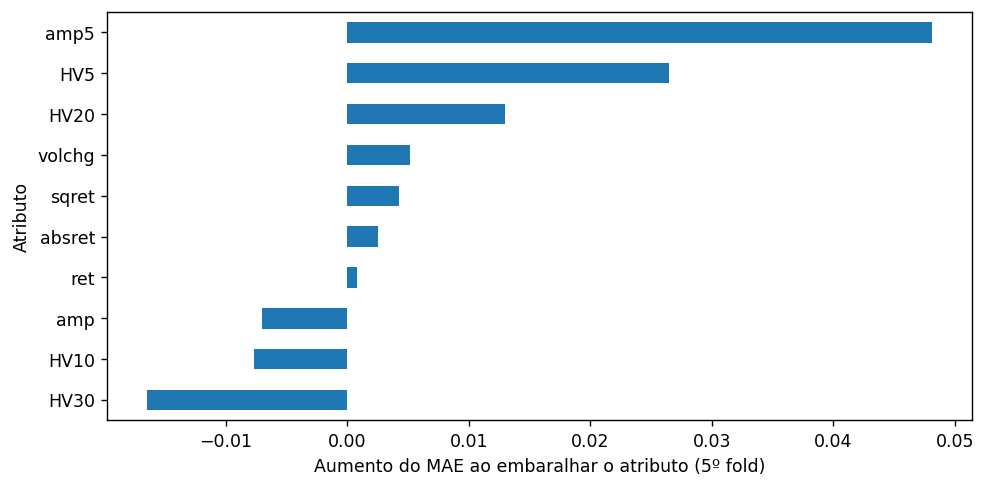

In [11]:
tr,va=splits[-1]
lin=make_model('Linear').fit(dev[FEATURES].iloc[tr],dev.y.iloc[tr]);rfpar=models_cv[(SET,'RF')][0]
forest=make_model('RF',rfpar).fit(dev[FEATURES].iloc[tr],dev.y.iloc[tr])
imp=pd.DataFrame({'Atributo':FEATURES,'Coeficiente_linear_padronizado':lin[-1].coef_,'Importancia_RF_impureza':forest.feature_importances_})
perm=permutation_importance(forest,dev[FEATURES].iloc[va],dev.y.iloc[va],scoring='neg_mean_absolute_error',n_repeats=5,random_state=42,n_jobs=-1)
imp['Permutation_delta_MAE']=perm.importances_mean
imp=imp.sort_values('Permutation_delta_MAE',ascending=False)
display(imp.round(4).head(15));imp.to_csv(OUT/'importancia_atributos.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));imp.head(10).sort_values('Permutation_delta_MAE').plot.barh(x='Atributo',y='Permutation_delta_MAE',legend=False,ax=ax);ax.set_xlabel('Aumento do MAE ao embaralhar o atributo (5º fold)');plt.tight_layout();plt.show()

## Teste 2024–2025 e segunda base
O conjunto de atributos, os parâmetros, pesos dos comitês e a regra de seleção são congelados antes de calcular métricas do teste. O USD/BRL PTAX possui alvo independente: volatilidade dos próximos cinco retornos cambiais, com os mesmos algoritmos e horizonte. A avaliação de 2024–2025 já fora observada em estudos anteriores do projeto, portanto a independência histórica do teste é limitada, embora esta nova busca e escolha não tenham usado esse período.

In [12]:
predtest=pd.DataFrame(index=test.index);predtest['Real']=test.y;predtest['HV5']=test.HV5
for label,features in CAND.items():
 for kind in ['Linear','SVR','RF']:
  param=models_cv[(label,kind)][0]
  m=make_model(kind,param).fit(dev[features],dev.y)
  predtest[f'{label}|{kind}']=m.predict(test[features])
predtest['Comitê simples']=predtest[[f'{SET}|{k}' for k in chosen_kinds]].mean(axis=1)
predtest['Comitê ponderado']=predtest[[f'{SET}|{k}' for k in chosen_kinds]].values@weights
records=[]
for _,r in full.iterrows():
 p=predtest[r.Conjunto+'|'+r.Modelo] if r.Modelo in chosen_kinds else predtest[r.Modelo]
 z=metr(predtest.Real,p)
 records.append({'Ativo':'PETR4','Conjunto':r.Conjunto,'Modelo':r.Modelo,'MAE_val':r.MAE,'sd_MAE_val':r.MAE_sd,'MSE_val':r.MSE,'RMSE_val':r.RMSE,'sd_RMSE_val':r.RMSE_sd,'R2_val':r.R2,
                 'MAE_teste':z['MAE'],'MSE_teste':z['MSE'],'RMSE_teste':z['RMSE'],'R2_teste':z['R2']})
bv=metr(dev.y.iloc[np.concatenate([va for _,va in splits])],dev.HV5.iloc[np.concatenate([va for _,va in splits])]);bt=metr(test.y,test.HV5)
records.insert(0,{'Ativo':'PETR4','Conjunto':'Histórico','Modelo':'HV5','MAE_val':basefold.MAE.mean(),'sd_MAE_val':basefold.MAE.std(),'MSE_val':basefold.MSE.mean(),'RMSE_val':basefold.RMSE.mean(),'sd_RMSE_val':basefold.RMSE.std(),'R2_val':basefold.R2.mean(),'MAE_teste':bt['MAE'],'MSE_teste':bt['MSE'],'RMSE_teste':bt['RMSE'],'R2_teste':bt['R2']})
results=pd.DataFrame(records)
display(results.round(4));print('MODELO SELECIONADO NA VALIDAÇÃO:',SET,choice.Modelo)
predtest.index.name='Date';predtest.to_csv(OUT/'previsoes_teste.csv')

MODELO SELECIONADO NA VALIDAÇÃO: PETR4-only SVR


   Ativo       Conjunto            Modelo  MAE_val  sd_MAE_val  MSE_val  RMSE_val  sd_RMSE_val  R2_val  MAE_teste  MSE_teste  RMSE_teste  R2_teste
0  PETR4      Histórico               HV5   1.1318      0.2311   3.3131    1.7115       0.6927 -0.6860     0.7291     1.0954      1.0466   -0.9080
1  PETR4     PETR4-only               SVR   0.8949      0.2701   2.9064    1.4873       0.9316 -0.0344     0.6877     0.7421      0.8614   -0.2926
2  PETR4  PETR4+USD_BRL               SVR   0.9079      0.2898   2.9670    1.4999       0.9469 -0.0434     0.7059     0.7921      0.8900   -0.3798
3  PETR4     PETR4-only            Linear   0.9258      0.1569   2.4582    1.4490       0.6694 -0.1406     0.7749     0.8644      0.9297   -0.5057
4  PETR4  PETR4+USD_BRL            Linear   0.9266      0.1569   2.4798    1.4536       0.6772 -0.1433     0.7894     0.8859      0.9412   -0.5431
5  PETR4  PETR4+USD_BRL                RF   0.9333      0.2271   2.6823    1.4918       0.7556 -0.1697     0.8266     

In [13]:
RFEATURES=COMMON
rd=F0.dropna(subset=RFEATURES+['HV5','y','TargetEnd']).copy()
rdev=rd[(rd.index<'2024-01-01')&(rd.TargetEnd<'2024-01-01')];rtest=rd[(rd.index>='2024-01-01')&(rd.index<='2025-12-31')]
rsplits=list(TimeSeriesSplit(n_splits=5,test_size=252,gap=5).split(rdev))
assert all(rdev.TargetEnd.iloc[tr].max()<rdev.index[va].min() for tr,va in rsplits)
print('USD_BRL:',len(rdev),'desenvolvimento;',len(rtest),'teste; folds:',[(len(tr),len(va)) for tr,va in rsplits])
rpred=pd.DataFrame(index=rtest.index);rpred['Real']=rtest.y;rpred['HV5']=rtest.HV5
rCV={};rrows=[];rparam={};rfoldpred={}
for kind,params in [('Linear',[None]),('SVR',[(.5,.1),(2,.1),(2,.3)]),('RF',[5,10])]:
 configs=[]
 for param in params:
  vals=[];pp=[]
  for tr,va in rsplits:
   m=make_model(kind,param).fit(rdev[RFEATURES].iloc[tr],rdev.y.iloc[tr]);pred=m.predict(rdev[RFEATURES].iloc[va]);vals.append(metr(rdev.y.iloc[va],pred));pp.append(pd.Series(pred,index=rdev.index[va]))
  z=pd.DataFrame(vals);configs.append((z.MAE.mean(),param,z,pd.concat(pp)))
 _,param,z,pp=min(configs,key=lambda v:v[0]);rparam[kind]=param;rCV[kind]=z;rfoldpred[kind]=pp
 m=make_model(kind,param).fit(rdev[RFEATURES],rdev.y);rpred[kind]=m.predict(rtest[RFEATURES])
 rt=metr(rpred.Real,rpred[kind]);rrows.append({'Ativo':'USD_BRL','Conjunto':'USD_BRL-only','Modelo':kind,'MAE_val':z.MAE.mean(),'sd_MAE_val':z.MAE.std(),'MSE_val':z.MSE.mean(),'RMSE_val':z.RMSE.mean(),'sd_RMSE_val':z.RMSE.std(),'R2_val':z.R2.mean(),'MAE_teste':rt['MAE'],'MSE_teste':rt['MSE'],'RMSE_teste':rt['RMSE'],'R2_teste':rt['R2']})
rw=np.array([1/rCV[k].MAE.mean() for k in chosen_kinds]);rw/=rw.sum()
rpred['Comitê simples']=rpred[chosen_kinds].mean(axis=1);rpred['Comitê ponderado']=rpred[chosen_kinds].values@rw
foldmatrix=pd.concat({k:rfoldpred[k] for k in chosen_kinds},axis=1)
for label in ['Comitê simples','Comitê ponderado']:
 vals=[]
 for tr,va in rsplits:
  mat=foldmatrix.loc[rdev.index[va],chosen_kinds]
  pp=mat.mean(axis=1) if label=='Comitê simples' else mat.values@rw
  vals.append(metr(rdev.y.iloc[va],pp))
 z=pd.DataFrame(vals);rt=metr(rpred.Real,rpred[label]);rrows.append({'Ativo':'USD_BRL','Conjunto':'USD_BRL-only','Modelo':label,'MAE_val':z.MAE.mean(),'sd_MAE_val':z.MAE.std(),'MSE_val':z.MSE.mean(),'RMSE_val':z.RMSE.mean(),'sd_RMSE_val':z.RMSE.std(),'R2_val':z.R2.mean(),'MAE_teste':rt['MAE'],'MSE_teste':rt['MSE'],'RMSE_teste':rt['RMSE'],'R2_teste':rt['R2']})
rb=pd.DataFrame([metr(rdev.y.iloc[va],rdev.HV5.iloc[va]) for tr,va in rsplits]);rt=metr(rpred.Real,rpred.HV5)
rrows.insert(0,{'Ativo':'USD_BRL','Conjunto':'Histórico','Modelo':'HV5','MAE_val':rb.MAE.mean(),'sd_MAE_val':rb.MAE.std(),'MSE_val':rb.MSE.mean(),'RMSE_val':rb.RMSE.mean(),'sd_RMSE_val':rb.RMSE.std(),'R2_val':rb.R2.mean(),'MAE_teste':rt['MAE'],'MSE_teste':rt['MSE'],'RMSE_teste':rt['RMSE'],'R2_teste':rt['R2']})
results=pd.concat([results,pd.DataFrame(rrows)],ignore_index=True)
results.to_csv(OUT/'resultados_modelos.csv',index=False)
rpred.index.name='Date';rpred.to_csv(OUT/'previsoes_teste_USD_BRL.csv');display(pd.DataFrame(rrows).round(4))

USD_BRL: 1970 desenvolvimento; 500 teste; folds: [(705, 252), (957, 252), (1209, 252), (1461, 252), (1713, 252)]


     Ativo      Conjunto            Modelo  MAE_val  sd_MAE_val  MSE_val  RMSE_val  sd_RMSE_val  R2_val  MAE_teste  MSE_teste  RMSE_teste  R2_teste
0  USD_BRL     Histórico               HV5   0.3601      0.0878   0.2293    0.4659       0.1236 -0.5271     0.2816     0.1418      0.3765   -0.6355
1  USD_BRL  USD_BRL-only            Linear   0.2919      0.0748   0.1585    0.3821       0.1250  0.0038     0.2255     0.0882      0.2970   -0.0177
2  USD_BRL  USD_BRL-only               SVR   0.2965      0.0837   0.1679    0.3915       0.1353 -0.0324     0.2147     0.0860      0.2933    0.0079
3  USD_BRL  USD_BRL-only                RF   0.3165      0.0674   0.1789    0.4107       0.1132 -0.2128     0.2389     0.0986      0.3140   -0.1371
4  USD_BRL  USD_BRL-only    Comitê simples   0.2960      0.0726   0.1613    0.3862       0.1233 -0.0232     0.2208     0.0876      0.2959   -0.0100
5  USD_BRL  USD_BRL-only  Comitê ponderado   0.2957      0.0728   0.1611    0.3859       0.1236 -0.0207     0.22

Erros absolutos maiores:
Comparação do modelo escolhido com HV5: {'MAE': 0.6877098380094309, 'MSE': 0.7420712124312707, 'RMSE': np.float64(0.8614355532663316), 'R2': -0.29259899194024097} baseline {'MAE': 0.7290960637387968, 'MSE': 1.0953577882827106, 'RMSE': np.float64(1.0465934207144199), 'R2': -0.9079818071762993}


   seed     MAE    RMSE
0    11  0.8020  0.9784
1    23  0.7982  0.9753
2    42  0.7911  0.9714
3    71  0.8023  0.9820
4   101  0.8153  0.9958

         MAE    RMSE
mean  0.8018  0.9806
std   0.0088  0.0094

              real  previsto    erro
Date                                
2024-03-06  5.3132    1.4785  3.8347
2024-03-07  5.3592    1.5360  3.8231
2024-03-01  5.2028    1.7407  3.4621
2024-03-05  5.6914    2.2347  3.4567
2024-03-04  5.1280    1.9566  3.1713
2025-04-04  4.3916    2.0018  2.3899
2024-04-12  0.5766    2.6394  2.0628
2025-04-03  3.9692    1.9521  2.0171
2024-08-22  3.4349    1.5040  1.9309
2024-08-19  3.3156    1.3959  1.9197

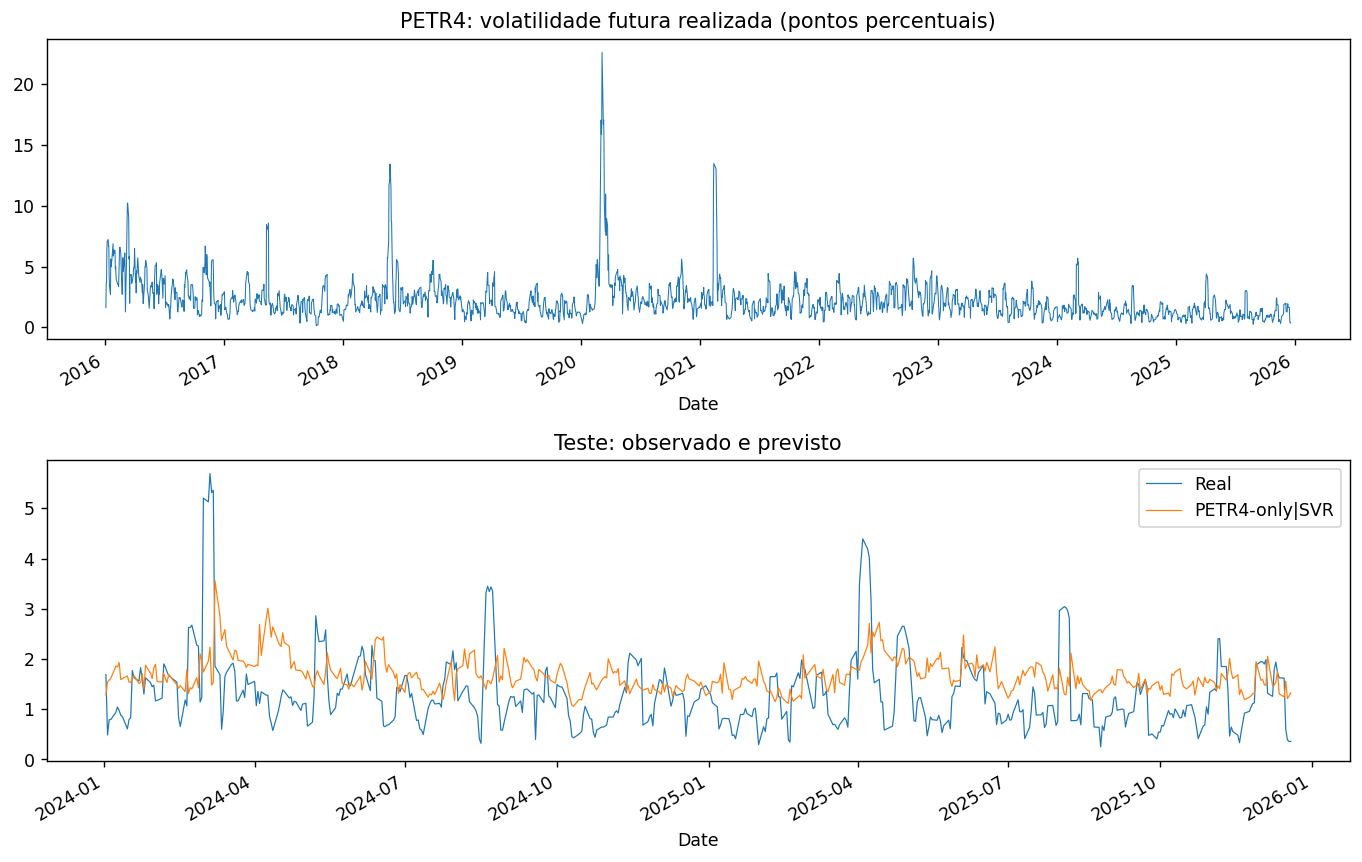

In [14]:
seedrows=[]
for seed in [11,23,42,71,101]:
 m=make_model('RF',models_cv[(SET,'RF')][0],seed).fit(dev[FEATURES],dev.y);z=metr(test.y,m.predict(test[FEATURES]));seedrows.append({'seed':seed,'MAE':z['MAE'],'RMSE':z['RMSE']})
seeds=pd.DataFrame(seedrows);display(seeds.round(4));display(seeds[['MAE','RMSE']].agg(['mean','std']).round(4))
final_col= SET+'|'+choice.Modelo if choice.Modelo in chosen_kinds else choice.Modelo
err=(predtest[final_col]-predtest.Real).abs()
print('Erros absolutos maiores:');display(pd.DataFrame({'real':predtest.Real,'previsto':predtest[final_col],'erro':err}).nlargest(10,'erro').round(4))
fig,axs=plt.subplots(2,1,figsize=(11,7));P.y.plot(ax=axs[0],linewidth=.6,title='PETR4: volatilidade futura realizada (pontos percentuais)');predtest[['Real',final_col]].plot(ax=axs[1],linewidth=.7,title='Teste: observado e previsto');plt.tight_layout();plt.show()
print('Comparação do modelo escolhido com HV5:',metr(test.y,predtest[final_col]),'baseline',bt)

In [15]:
# Arquivos abertos de resultados, dados e auditoria
results.to_csv(OUT/'resultados_modelos.csv',index=False)
P[RAW+EXT+XFX+['y','TargetEnd','FX_ObsDate']].to_csv(OUT/'dados_preparados_PETR4.csv')
F0[RAW+COMMON+['y','TargetEnd','HV5']].to_csv(OUT/'dados_preparados_USDBRL.csv')
imp.to_csv(OUT/'importancia_atributos.csv',index=False)
pd.DataFrame({'seed':seeds.seed,'MAE':seeds.MAE,'RMSE':seeds.RMSE}).to_csv(OUT/'sensibilidade_sementes.csv',index=False)
print('Comparação realizada:');display(results.sort_values(['Ativo','MAE_teste']).round(4))

Comparação realizada:


      Ativo       Conjunto            Modelo  MAE_val  sd_MAE_val  MSE_val  RMSE_val  sd_RMSE_val  R2_val  MAE_teste  MSE_teste  RMSE_teste  R2_teste
1     PETR4     PETR4-only               SVR   0.8949      0.2701   2.9064    1.4873       0.9316 -0.0344     0.6877     0.7421      0.8614   -0.2926
2     PETR4  PETR4+USD_BRL               SVR   0.9079      0.2898   2.9670    1.4999       0.9469 -0.0434     0.7059     0.7921      0.8900   -0.3798
0     PETR4      Histórico               HV5   1.1318      0.2311   3.3131    1.7115       0.6927 -0.6860     0.7291     1.0954      1.0466   -0.9080
8     PETR4     PETR4-only  Comitê ponderado   0.8985      0.1953   2.5836    1.4522       0.7704 -0.0753     0.7434     0.8206      0.9059   -0.4294
7     PETR4     PETR4-only    Comitê simples   0.8989      0.1947   2.5818    1.4523       0.7686 -0.0768     0.7443     0.8223      0.9068   -0.4324
3     PETR4     PETR4-only            Linear   0.9258      0.1569   2.4582    1.4490       0.6694 -0

## Conclusão metodológica
As duas tarefas são regressões. Para volatilidade, as unidades de erro dependem da escala de cada série: compare modelos **dentro** de cada ativo, e use erro relativo ao HV5 para comparar melhoria. Comitês combinam Linear, SVR e RF, com pesos inversos ao MAE de validação. Coeficientes e permutation importance indicam associações, sem inferência causal. A relação cambial com PETR4 é hipótese preditiva, não evidência de transmissão causal. As observações de alvos com janelas futuras sobrepostas não são independentes. A etapa GPT zero-shot/few-shot está reservada para o final e não se afirma qualquer resultado dela.